In [10]:
import json, math, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier, RandomForestClassifier
from sklearn.metrics import confusion_matrix

DATA_DIR = Path('data')
TEST_FRAC = 0.2   # what % of data is tested on at the end
SEED = 0

In [ ]:
def read_jsonl(raw):
    dec = json.JSONDecoder()
    for line in raw.decode('utf-8').splitlines():
        line, pos = line.strip(), 0
        if not line or line.startswith('#'):
            continue
        while pos < len(line):
            obj, pos = dec.raw_decode(line, pos)
            yield obj
            while pos < len(line) and line[pos].isspace():
                pos += 1

#flags data as either plain or background
def load_trials():
    # skip anything named test (data/test.jsonl, data/test/...): those are long recordings, not training trials
    files = sorted(f for f in DATA_DIR.rglob('*.jsonl') if 'test' not in f.relative_to(DATA_DIR).with_suffix('').parts)
    trials = []
    for f in files:
        base = re.sub(r'_AD$', '', re.sub(r'_\d+$', '', f.stem))
        flag = 'background' if base.endswith('_background') else 'plain'
        site = base[:-len('_background')] if flag == 'background' else base
        recs = sorted((r for r in read_jsonl(f.read_bytes()) if r.get('trace')), key=lambda r: r['ts'])
        n_test = math.ceil(len(recs) * TEST_FRAC)
        for i, r in enumerate(recs):
            trace = np.asarray(r['trace'], dtype=np.float64)
            dur = (r.get('durationMs') or 10000) / 1000
            times = (np.asarray(r['times'], dtype=np.float64) / 1000 if r.get('times') is not None
                     else (np.arange(len(trace)) + 0.5) * dur / len(trace))
            trials.append(dict(trace=trace, times=times, site=site, flag=flag,
                               test=i >= len(recs) - n_test))
    return trials

trials = load_trials()
SITES = sorted({t['site'] for t in trials}, key=lambda s: (s != 'idle', s))
site = np.array([t['site'] for t in trials], dtype=object)
flag = np.array([t['flag'] for t in trials], dtype=object)
test = np.array([t['test'] for t in trials])
train = ~test

print(f'{len(trials)} trials | train {train.sum()}, test {test.sum()}\n')
print(f'  {"site":<12}{"plain":>7}{"background":>12}')
for s in SITES:
    print(f'  {s:<12}{((site == s) & (flag == "plain")).sum():>7}{((site == s) & (flag == "background")).sum():>12}')

1602 trials | train 1281, test 321

  site          plain  background
  idle            100         100
  chatgpt         100         100
  coupang         102         100
  figma           100         100
  google          100         100
  instagram       100         100
  navermap        100         100
  youtube         100         100


In [ ]:
USE_S = 10.0                  # seconds from the start of the recording (the site opens at 2 s)
BIN_S = 0.1                   # bin width
SPIKE_MS = 0.5                # latencies are clipped to this before averaging
SPIKE_THRESHOLDS = (SPIKE_MS, 2.0)
BASELINE = (0.5, 2.0)         # pre-open window used for normalisation

def features(t):
    #splits data into exactly 100 bins of 0.1s
    n_bins = int(round(USE_S / BIN_S))
    keep = t['times'] < USE_S 
    idx = np.minimum((t['times'][keep] / BIN_S).astype(int), n_bins - 1) 

    lat = np.clip(t['trace'][keep], 0, SPIKE_MS) #clips spikes to 0.5ms max
    base = slice(int(BASELINE[0] / BIN_S), int(BASELINE[1] / BIN_S)) #used to calculate baseline latency
    count = np.bincount(idx, minlength=n_bins).astype(float) #count the amount of reads in each bin

    n = np.maximum(count, 1) #prevents division by 0
    mean = np.bincount(idx, lat, n_bins) / n #mean latency in each bin
    rel_mean = mean / mean[base].mean()                          # mean latency, x baseline
    rel_count = count / max(count[base].mean(), 1e-9)            # reads per bin, x baseline
    spikes = [np.bincount(idx, t['trace'][keep] > thr, n_bins) / n for thr in SPIKE_THRESHOLDS] #spikes over 0.5ms and 2ms
    sd = np.sqrt(np.maximum(np.bincount(idx, lat ** 2, n_bins) / n - mean ** 2, 0))
    rel_sd = sd / max(mean[base].mean(), 1e-9)                   # spread, x baseline mean
    return np.concatenate([rel_mean, rel_count, *spikes, rel_sd])

X = np.stack([features(t) for t in trials])
assert np.isfinite(X).all()
print(f'{X.shape[1]} features per trial')

500 features per trial


In [ ]:
# Using RandomForest as it works well on noisy data
def random_forest():
    return RandomForestClassifier(n_estimators=1000, max_features=0.5, random_state=SEED, n_jobs=-1)

class Hierarchical:
    """Router picks plain vs background; that kind's expert names the site."""
    def __init__(self):
        self.router = random_forest()
        self.experts = {'plain': random_forest(), 'background': random_forest()}

    def fit(self, X, site, flag):
        self.router.fit(X, flag)
        for k, m in self.experts.items():
            m.fit(X[flag == k], site[flag == k])
        return self

    def predict(self, X):
        route = self.router.predict(X)
        out = np.empty(len(X), dtype=object)
        for k, m in self.experts.items():
            if (route == k).any():
                out[route == k] = m.predict(X[route == k])
        return out, route

In [20]:
flat = random_forest().fit(X[train], site[train])
hier = Hierarchical().fit(X[train], site[train], flag[train])
print('trained')

trained


Accuracy, 8 sites (random guess 0.125)

                 train    test
flat             1.000   0.869
hierarchical     1.000   0.888
  router                 0.994   (plain vs background)

Test accuracy by kind of trial
  plain       flat 0.894   hierarchical 0.888   (161 trials)
  background  flat 0.844   hierarchical 0.887   (160 trials)


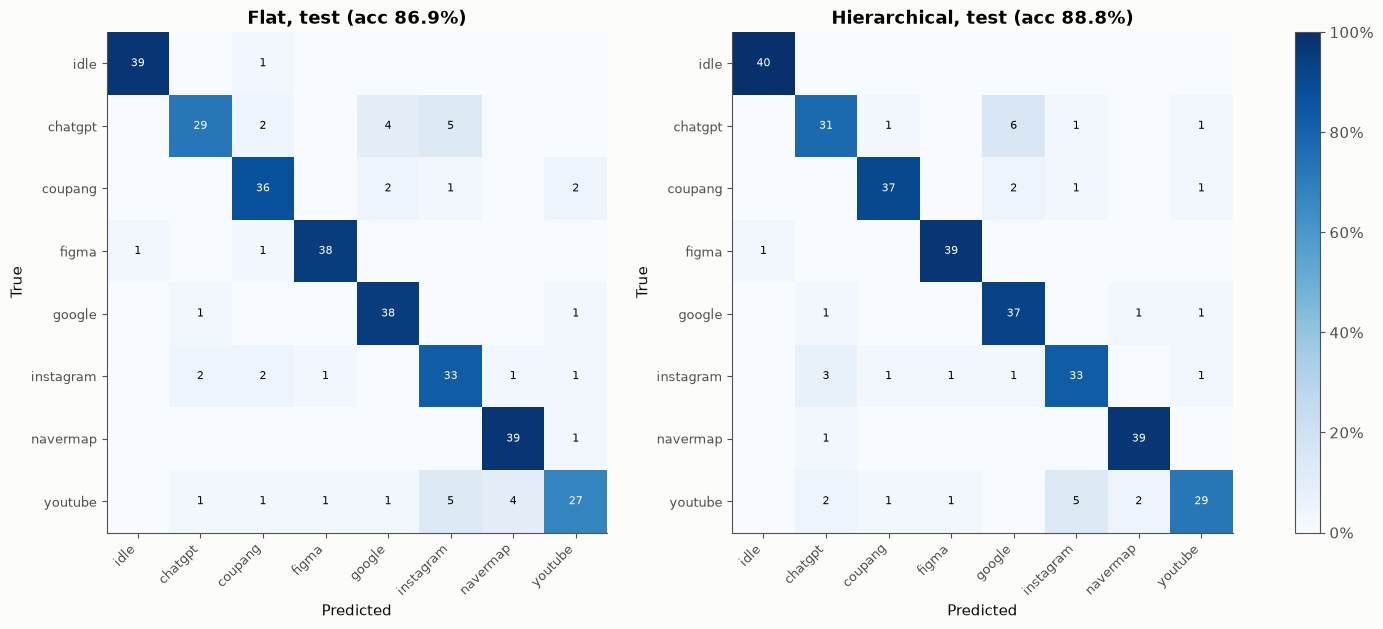

In [21]:
def plot_cm(ax, true, pred, names, title):
    cm = confusion_matrix(true, pred, labels=names)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                        color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(names)), names, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(names)), names, fontsize=9)
    ax.set(xlabel='Predicted', ylabel='True', title=title)
    ax.grid(False)
    return im

acc = lambda p, t: np.mean(p == t)
st, ft = site[test], flag[test]
pred_flat = flat.predict(X[test])
pred_hier, route = hier.predict(X[test])
train_flat = flat.predict(X[train])
train_hier, _ = hier.predict(X[train])

print(f'Accuracy, {len(SITES)} sites (random guess {1 / len(SITES):.3f})\n')
print(f'{"":<14}{"train":>8}{"test":>8}')
print(f'{"flat":<14}{acc(train_flat, site[train]):>8.3f}{acc(pred_flat, st):>8.3f}')
print(f'{"hierarchical":<14}{acc(train_hier, site[train]):>8.3f}{acc(pred_hier, st):>8.3f}')
print(f'{"  router":<14}{"":>8}{acc(route, ft):>8.3f}   (plain vs background)')

print('\nTest accuracy by kind of trial')
for f in ('plain', 'background'):
    sel = ft == f
    print(f'  {f:<11} flat {acc(pred_flat[sel], st[sel]):.3f}   hierarchical {acc(pred_hier[sel], st[sel]):.3f}   ({sel.sum()} trials)')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_cm(axes[0], st, pred_flat, SITES, f'Flat, test (acc {acc(pred_flat, st):.1%})')
im = plot_cm(axes[1], st, pred_hier, SITES, f'Hierarchical, test (acc {acc(pred_hier, st):.1%})')
fig.colorbar(im, ax=axes, fraction=0.025, format=PercentFormatter(1))
plt.show()

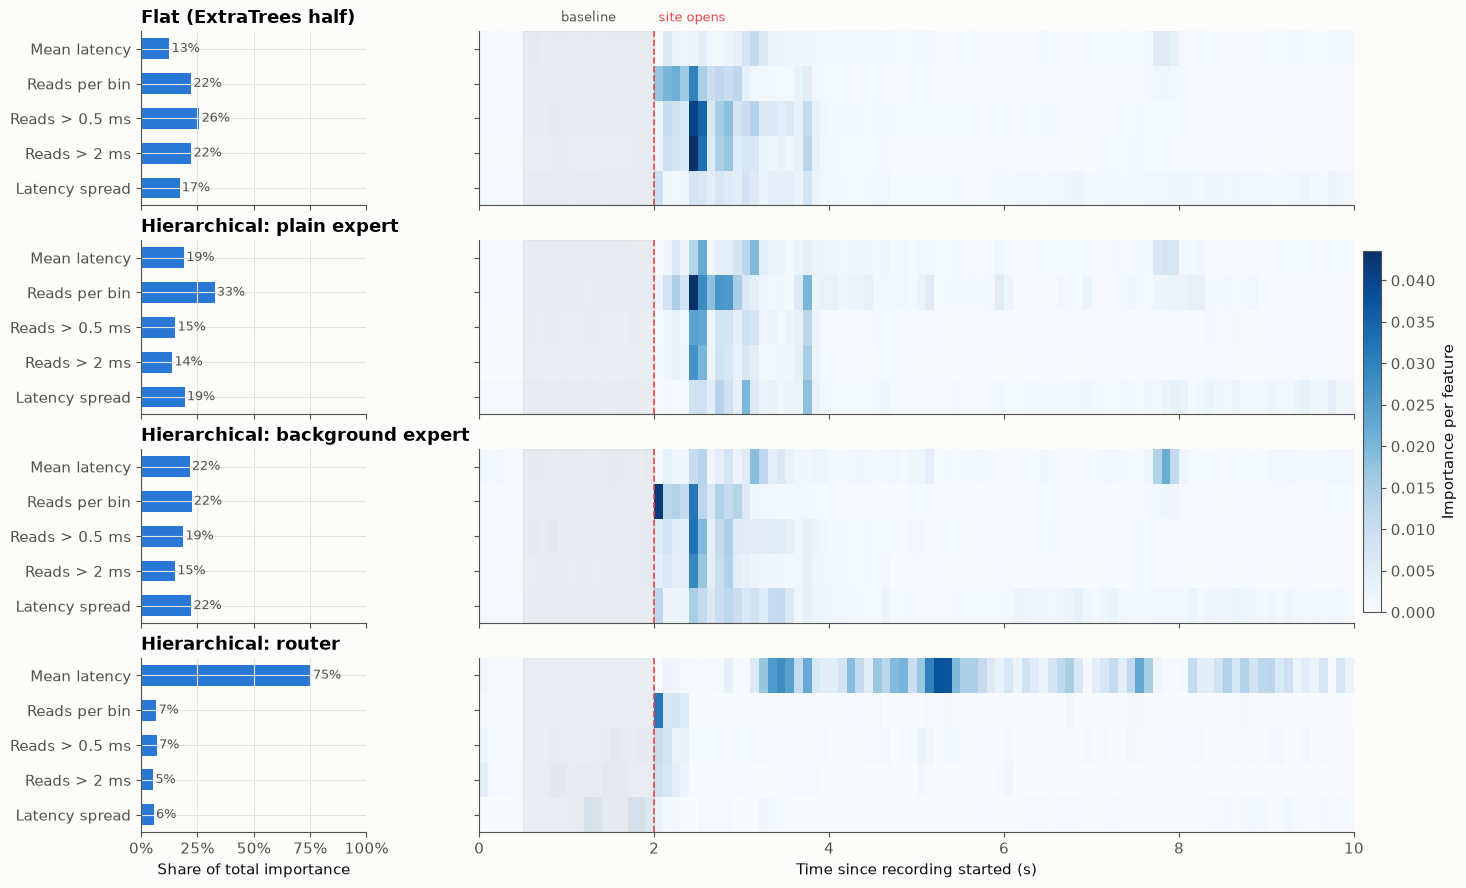

In [9]:
# Feature importance (RandomForest impurity importance, measured on the training data).
BLOCKS = ['Mean latency', 'Reads per bin', f'Reads > {SPIKE_THRESHOLDS[0]:g} ms',
          f'Reads > {SPIKE_THRESHOLDS[1]:g} ms', 'Latency spread']
n_bins = int(round(USE_S / BIN_S))
models = {'Flat': flat,
          'Hierarchical: plain expert': hier.experts['plain'],
          'Hierarchical: background expert': hier.experts['background'],
          'Hierarchical: router': hier.router}
imp = {name: m.feature_importances_.reshape(len(BLOCKS), n_bins) for name, m in models.items()}
vmax = max(v.max() for v in imp.values())

fig, axes = plt.subplots(len(models), 2, figsize=(16, 2.6 * len(models)),
                         gridspec_kw=dict(width_ratios=[1, 4]), sharex='col', sharey=True)
for (name, I), (ax_bar, ax_map) in zip(imp.items(), axes):
    # left: share of the model's importance in each measurement
    share = I.sum(1)
    ax_bar.barh(range(len(BLOCKS)), share, color='#2a78d6', height=0.6)
    for i, v in enumerate(share):
        ax_bar.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9, color='#52514e')
    ax_bar.set_xlim(0, 1)
    ax_bar.set_title(name, loc='left', fontweight='bold')
    ax_bar.xaxis.set_major_formatter(PercentFormatter(1))
    ax_bar.invert_yaxis()
    # right: where in time that importance sits
    im = ax_map.imshow(I, aspect='auto', cmap='Blues', vmin=0, vmax=vmax, interpolation='nearest',
                       extent=(0, USE_S, len(BLOCKS) - 0.5, -0.5))
    ax_map.axvline(2, color='#e34948', lw=1.2, ls='--')
    ax_map.axvspan(*BASELINE, color='#52514e', alpha=0.08)
    ax_map.grid(False)
axes[0, 1].text(2.05, -0.7, 'site opens', color='#e34948', fontsize=9, va='bottom')
axes[0, 1].text(sum(BASELINE) / 2, -0.7, 'baseline', color='#52514e', fontsize=9, va='bottom', ha='center')
for ax in axes[:, 0]:
    ax.set_yticks(range(len(BLOCKS)), BLOCKS)
axes[-1, 0].set_xlabel('Share of total importance')
axes[-1, 1].set_xlabel('Time since recording started (s)')
fig.colorbar(im, ax=axes[:, 1], fraction=0.02, pad=0.01, label='Importance per feature')
plt.show()

In [23]:
# ---- Find site visits in a long trace ----
# The models only know 10 s windows where a site opens at 2 s. So slide a 10 s window along the
# long trace and ask the model about every position:
#   1. visit score = 1 - P(idle). It is high when a site opens about 2 s into the window.
#   2. Take the highest-scoring window, call it a visit, and name the site from that same window.
#      The score peaks within ~0.1 s of the real visit, which matters: the models lean on the
#      first 0.1-0.5 s after the site opens.
#   3. Skip windows within MIN_GAP_S of that visit and repeat until no score is above THRESHOLD.
# The trace needs ~2 s of quiet before each visit (the baseline), and visits closer than MIN_GAP_S merge.

STEP_S = 0.1      # how far the window slides each step
MIN_GAP_S = 8.0   # two visits must be at least this far apart
THRESHOLD = 0.5   # minimum visit score to count as a visit
OPEN_S = 2.0      # where the site opens inside a training window

def window(trace, times, t0):
    """The USE_S seconds of the long trace starting at t0, re-timed so the window starts at 0."""
    lo, hi = np.searchsorted(times, [t0, t0 + USE_S])
    return dict(trace=trace[lo:hi], times=times[lo:hi] - t0)

def site_proba(model, X):
    """P(site) for each row, columns in SITES order. Works for the flat and the hierarchical model."""
    if hasattr(model, 'experts'):
        route = model.router.predict(X)
        parts = [(route == k, m) for k, m in model.experts.items()]
    else:
        parts = [(np.ones(len(X), bool), model)]
    P = np.zeros((len(X), len(SITES)))
    for sel, m in parts:
        if sel.any():
            P[np.ix_(sel, [SITES.index(c) for c in m.classes_])] = m.predict_proba(X[sel])
    return P

def find_visits(trace, times, model):
    """Returns (visits, starts, P). Each visit is a dict: time (s), site, confidence, score."""
    starts = np.arange(0, times[-1] - USE_S + STEP_S + 1e-9, STEP_S)   # last window may miss < STEP_S at the end
    if len(starts) == 0:
        raise ValueError(f'trace must be longer than {USE_S:g} s')
    Xw = np.stack([features(window(trace, times, t0)) for t0 in starts])
    Xw = np.nan_to_num(Xw, nan=0.0, posinf=0.0, neginf=0.0)   # windows with no reads in the baseline
    P = site_proba(model, Xw)
    score = 1 - P[:, SITES.index('idle')]
    Q = P.copy(); Q[:, SITES.index('idle')] = 0                # site probabilities without idle
    taken, visits = np.zeros(len(starts), bool), []
    for i in np.argsort(-score, kind='stable'):
        if score[i] < THRESHOLD:
            break
        if taken[i]:
            continue
        taken |= np.abs(starts - starts[i]) < MIN_GAP_S
        visits.append(dict(time=starts[i] + OPEN_S, site=SITES[Q[i].argmax()],
                           confidence=Q[i].max(), score=score[i]))
    return sorted(visits, key=lambda v: v['time']), starts, P

def load_long_traces(path):
    """Every recording in a recorder .jsonl file -> list of (record, trace ms, times s)."""
    out = []
    for r in read_jsonl(Path(path).read_bytes()):
        if not r.get('trace'):
            continue
        if r.get('times') is None:
            raise ValueError('recording has no per-read times; record it with the current recorder')
        out.append((r, np.asarray(r['trace'], dtype=np.float64), np.asarray(r['times'], dtype=np.float64) / 1000))
    return out

def plot_visits(visits, starts, P, title='Detected visits'):
    score = 1 - P[:, SITES.index('idle')]
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(starts + OPEN_S, score, color='#2a78d6', lw=2)
    ax.axhline(THRESHOLD, color='#52514e', lw=1, ls='--')
    ax.text(starts[0] + OPEN_S, THRESHOLD + 0.02, 'threshold', color='#52514e', fontsize=9)
    for v in visits:
        ax.plot(v['time'], 1.05, 'v', color='#2a78d6', ms=8)
        ax.text(v['time'], 1.1, f"{v['site']}\n{v['confidence']:.0%}", ha='center', va='bottom', fontsize=9)
    ax.set(ylim=(-0.05, 1.3), xlim=(0, starts[-1] + USE_S), yticks=[0, 0.5, 1],
           xlabel='Time in the long trace (s)', ylabel='Visit score')
    ax.set_title(title, loc='left', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()

1 recording(s) in data/test.jsonl

Recording 1 (2026-11-24T10:22:05.928Z, 50 s): 3 visit(s)
   time (s)  site       confidence
        2.3  figma             33%
       12.6  instagram         17%
       22.6  figma             38%


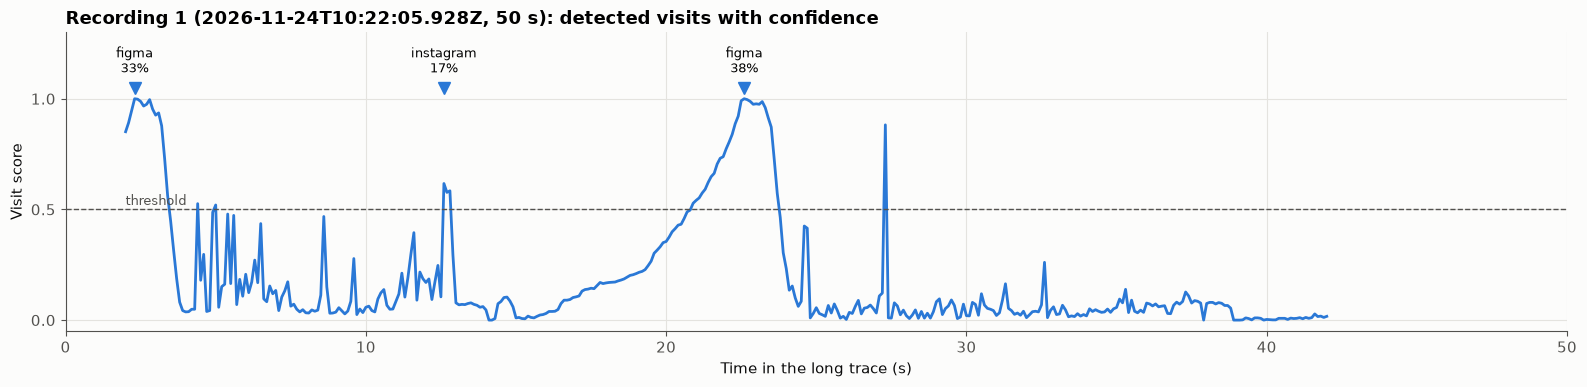

In [24]:
# Find the visits in every recording in data/test.jsonl.
# load_trials skips that file, so these recordings are never used for training.
LONG_FILE = DATA_DIR / 'test.jsonl'
MODEL = hier   # or flat

recordings = load_long_traces(LONG_FILE)
print(f'{len(recordings)} recording(s) in {LONG_FILE}')
for n, (rec, trace, times) in enumerate(recordings, 1):
    visits, starts, P = find_visits(trace, times, MODEL)
    name = f"Recording {n} ({rec.get('startedAt', 'no start time')}, {times[-1]:.0f} s)"
    print(f'\n{name}: {len(visits)} visit(s)')
    if visits:
        print(f'  {"time (s)":>9}  {"site":<11}{"confidence":>10}')
    for v in visits:
        print(f"  {v['time']:>9.1f}  {v['site']:<11}{v['confidence']:>10.0%}")
    plot_visits(visits, starts, P, title=f'{name}: detected visits with confidence')
